## Εργασία 1 ##

Καλωσήρθατε στην πρώτη σας εργασία. Η εργασία αυτή έχει σκοπό να σας βοηθήσει να εμπεδώσετε τα γραμμικά μοντέλα.

Τα Jupyter Notebooks είναι αλληλεπιδραστικά περιβάλλοντα προγραμματισμού ενσωματωμένα σε μια ιστοσελίδα. Στο μάθημα "Μηχανική Μάθηση" τα χρησιμοποιούμε στο πρακτικό μέρος του μαθήματος.

Στην εργασία αυτή θα πρέπει να συμπληρώσετε κώδικα Python 3 στα σημεία που αναφέρουν # YOUR CODE HERE. Μην τροποποιείτε τον κώδικα που βρίσκεται εκτός αυτών των περιοχών.

Πρωτού παραδόσετε την εργασία σας σιγουρευτείτε ότι ο κώδικας σε όλα τα κελιά τρέχει σωστά. Για το σκοπό αυτό επιλέξτε από το μενού **Χρόνος εκτέλεσης (runtime) -> Επανεκίνηση περιόδου λειτουργίας και εκτέλεση όλων**.

Συμπληρώστε το όνομα (**NAME**) και το **AEM** σας παρακάτω:

In [27]:
NAME = "Lavdakis Giorgos"
AEM = "10672"

## Μέρος Α: 5 μονάδες ##

Σε αυτό το μέρος της άσκησης θα χτίσουμε ένα μοντέλο γραμμικής παλινδρόμησης από το μηδέν.

**Α1 (1 μονάδα):** Υλοποιήστε τη σιγμοειδή συνάρτηση $\sigma(z)= \dfrac{1}{1 + exp(-z)}$ με τη NumPy.

In [28]:
import numpy as np

def sigmoid(z):
    """Υπολογίζει τη σιγμοειδή συνάρτηση."""
    x = 1 / (1 + np.exp(-z))
    return x

In [29]:
"""Τεστ ορθού υπολογισμού σιγμοειδούς."""
assert sigmoid(0) == 0.5
assert np.round(sigmoid(7),8) == 0.99908895
assert np.round(sigmoid(-1),8) == 0.26894142

**Α2 (4 μονάδες):** Υλοποιήστε κλάση για τον αλγόριθμο της λογιστικής παλινδρόμησης. Αρχικοποιήστε τις παραμέτρους σε μηδενικές τιμές. Αποθηκεύστε τες στο διάνυσμα στήλη theta. Η συνάρτηση fit πρέπει να δέχεται πίνακα X με τις τιμές των μεταβλητών εισόδου και διάνυσμα στήλη y με τις τιμές της μεταβλητής εξόδου. Η συνάρτηση predict πρέπει να δέχεται πίνακα Χ με τις τιμές των μεταβλητών εισόδου.

In [30]:
class MyLogisticRegression:
    def __init__(self, num_iterations=2000, learning_rate=0.004):
      self.theta = None
      self.num_iterations = num_iterations
      self.learning_rate = learning_rate

    def fit(self, X, y):
      m, n = X.shape 
      X = np.c_[np.ones(m), X] # Add bias term
      self.theta = np.zeros((n + 1, 1)) 
      y = y.reshape(m, 1) 
      for _ in range(self.num_iterations): # Update weights with gradient descent
        z = np.dot(X, self.theta) # Linear combination
        h = sigmoid(z) 
        gradient = (1 / m) * np.dot(X.T, (h - y)) 
        self.theta -= self.learning_rate * gradient 

    def predict(self, X):
      m = X.shape[0]
      X = np.c_[np.ones(m), X] # Add bias term
      z = np.dot(X, self.theta) # Linear combination
      probabilities = sigmoid(z) # Output of model
      return (probabilities >= 0.5).astype(int) # Binary classification 

In [31]:
"""Τεστ ορθής λειτουργίας fit"""
from sklearn.datasets import make_blobs

# δημιουργία δύο ομάδων από τυχαία σημεία με κέντρο 0,0,0 και 3,3,3 και τυπική απόκλιση 1
centers = [[0.0, 0.0, 0.0], [3.0, 3.0, 3.0]]
X, y = make_blobs(n_samples=200, centers=centers,
                  random_state=47, shuffle=False)
y = np.array(y).reshape(-1,1)

lr = MyLogisticRegression()
lr.fit(X, y)

assert np.allclose(lr.theta, np.array([[-1.1772064],[0.5026043],[0.40811666],[0.55685573]]))

In [32]:
"""Τεστ ορθής λειτουργίας predict"""
from sklearn.datasets import make_blobs

# δημιουργία δύο ομάδων από τυχαία σημεία με κέντρο 0,0,0 και 3,3,3 και τυπική απόκλιση 1
centers = [[0.0, 0.0, 0.0], [3.0, 3.0, 3.0]]
X, y = make_blobs(n_samples=200, centers=centers,
                  random_state=47, shuffle=False)
y = np.array(y).reshape(-1,1)

lr = MyLogisticRegression()
lr.fit(X, y)

assert np.allclose(lr.predict(X[[0,199],:]), np.array([[0],[1]]))

## Μέρος B: Χρήση μοντέλου στο σύνολο digits (3 μονάδες)

Σε αυτό το μέρος θα δουλέψουμε με το σύνολο δεδομένων digits (https://scikit-learn.org/stable/datasets/toy_dataset.html#digits-dataset), το οποίο αφορά μια εργασία αναγνώρισης ψηφίων (0 έως 9) από δυαδικές εικόνες  διαστάσεων 32x32 με χειρόγραφα ψηφία, οι οποίες χωρίστηκαν σε 64 (8x8) τμήματα των 4x4 δυαδικών στοιχείων, και σε κάθε ένα από αυτά τα 64 τμήματα μετρήθηκαν πόσα από τα 16 (4x4) στοιχεία είχε τιμή 1.

Αρχικά θα φορτώσουμε τα δεδομένα

In [33]:
from sklearn.datasets import load_digits
digits = load_digits()
X = digits.data
y = digits.target

**Β1 (1 μονάδα)**: Χρησιμοποιήστε την κλάση OneVsOneClαssifier της sklearn σε συνδυασμό με την κλάση LogisticRegression για να εκπαιδεύσετε ένα μοντέλο λογιστικής παλινδρόμησης για κάθε ζεύγος κλάσης. Χρησιμοποιήστε προκαθορισμένες ρυθμίσεις στις παραμέτρους της κλάσης LogisticRegression, αλλά θέστε τον μέγιστο αριθμό επαναλήψεων σε 1000 και την παράμετρο random_state σε 42. Ονομάστε ovo το αντικείμενο της κλάσης.

In [34]:
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsOneClassifier

ovo = OneVsOneClassifier(LogisticRegression(max_iter=1000, random_state=42)) 
ovo.fit(X, y) 

,estimator,LogisticRegre...ndom_state=42)
,n_jobs,None
,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'


In [35]:
#έλεγχος ορθής λειτουργίας
assert len(ovo.estimators_) == 45
assert ovo.estimators_[0].coef_.shape == (1, 64)

**Β2 (0,5 μονάδες)**: Χρησιμοποιήστε την κλάση OneVsRestClαssifier της sklearn σε συνδυασμό με την κλάση LogisticRegression για να εκπαιδεύσετε ένα μοντέλο λογιστικής παλινδρόμησης για κάθε κλάση. Χρησιμοποιήστε προκαθορισμένες ρυθμίσεις στις παραμέτρους της κλάσης LogisticRegression, αλλά θέστε τον μέγιστο αριθμό επαναλήψεων σε 1000 και την παράμετρο random_state σε 42. Ονομάστε ovr το αντικείμενο της κλάσης.

In [36]:
from sklearn.multiclass import OneVsRestClassifier

ovr = OneVsRestClassifier(LogisticRegression(max_iter=1000, random_state=42)) 
ovr.fit(X, y) 

,estimator,LogisticRegre...ndom_state=42)
,n_jobs,None
,verbose,0
,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42


In [37]:
#έλεγχος ορθής λειτουργίας
assert len(ovr.estimators_) == 10
assert ovr.estimators_[0].coef_.shape == (1, 64)

**Β3 (1 μονάδα)**: Ορίστε συνάρτηση που δέχεται ένα μοντέλο, και ένα σύνολο δεδομένων, συγκρίνει τις πραγματικές τιμές της μεταβλητής εξόδου με τις προβλέψεις του μοντέλου χρησιμοποιώντας τη συνάρτηση predict του μοντέλου και επιστρέφει τους δείκτες των παραδειγμάτων τα οποία το μοντέλο ταξινομεί εσφαλμένα.

In [38]:
def find_misclassified(classifier, input, output):
  predictions = classifier.predict(input) 
  misclassified_indices = np.array([i for i, (true, pred) in enumerate(zip(output, predictions)) if true != pred])
  # Check if predictions with real data are different and find their indexes 
  return misclassified_indices 

In [39]:
#έλεγχος ορθής λειτουργίας
output = find_misclassified(ovr, X, y)
expected = np.array([524, 890, 1553, 1658])
np.testing.assert_array_equal(output, expected)

Μια εικόνα που δεν τα πάει καλά το μοντέλο είναι η 525η με δείκτη 524. Το μοντέλο προβλέπει τον αριθμό 3, ενώ η εικόνα (υποτίθεται ότι) απεικονίζει τον αριθμό 8.

In [40]:
print(ovr.predict(X[524:525]))
print(y[524:525])

[3]
[8]


Εμφανίζοντας την εικόνα μπορούμε να διαπιστώσουμε γιατί δυσκολεύεται το μοντέλο με τα ίδια μας τα μάτια.

Matplotlib is building the font cache; this may take a moment.


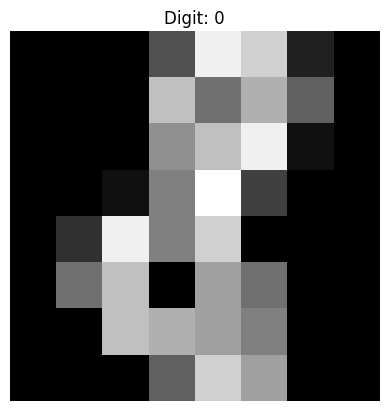

In [41]:
from matplotlib import pyplot as plt

image = digits.images[524]

# Plot the image
plt.imshow(image, cmap='gray')
plt.title(f'Digit: {digits.target[0]}')  # Show the corresponding label
plt.axis('off')  # Turn off the axis labels
plt.show()

**Β4 (0,5 μονάδες)**: Τέλος χρησιμοποιήστε την κλάση LogisticRegression απο μόνη της για να εκπαιδεύσετε ένα μοντέλο πολυχοτομικής λογιστικής παλινδρόμησης. Χρησιμοποιήστε προκαθορισμένες ρυθμίσεις στις παραμέτρους της κλάσης LogisticRegression, αλλά θέστε τον μέγιστο αριθμό επαναλήψεων σε 1000 και την παράμετρο random_state σε 42. Ονομάστε clf το αντικείμενο της κλάσης.

In [42]:
clf = LogisticRegression(max_iter=1000, random_state=42) 
clf.fit(X, y) 

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [43]:
#έλεγχος ορθής λειτουργίας
assert clf.coef_.shape == (10, 64)

## Μέρος Γ: Χρήση μοντέλου στο σύνολο breast cancer (2 μονάδες)

Σε αυτό το μέρος θα δουλέψουμε με το σύνολο δεδομένων breast cancer (https://scikit-learn.org/stable/datasets/toy_dataset.html#breast-cancer-dataset), το οποίο αφορά την ταξινόμηση ψηφιακών εικόνων μικροσκοπίου με κύτταρα που έχουν εξαχθεί από μαστό μέσω βιοψίας με λεπτή βελόνα.

In [44]:
from sklearn.datasets import load_breast_cancer
bca = load_breast_cancer()
X = bca.data
y = bca.target

**Γ1 (1 μονάδα)**: Επειδή τα εύρη τιμών των μεταβλητών διαφέρουν, εφαρμόστε προτυποποίηση στα δεδομένα εισόδου.

In [45]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler() 
scaler.fit(X) # Compute mean and std
X = scaler.transform(X) # Apply standardization

In [46]:
#έλεγχος ορθής λειτουργίας
assert np.allclose(np.mean(X,axis=0), np.zeros(30), atol=0.01)

Παρακάτω εκπαιδεύουμε ένα μοντέλο λογιστικής παλινδρόμησης με προκαθορισμένες ρυθμίσεις στις παραμέτρους και παράμετρο random_state ίση με 42.

In [47]:
clf = LogisticRegression(random_state=42)
clf.fit(X,y)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


**Γ2 (1 μονάδα)**: Υλοποιήστε συνάρτηση που δέχεται μοντέλο λογιστικής παλινδρόμησης δυαδικής ταξινόμησης σαν το παραπάνω καθώς και πίνακα συμβολοσειρών με τα ονόματα των μεταβλητών εισόδου και επιστρέφει τη σημαντικότερη μεταβλητή εισόδου.

In [48]:
def best_feature(model, feature_names):
  theta_abs = np.abs(model.coef_[0]) # Absolute values of parameters 
  best_idx = np.argmax(theta_abs) # Index of the max absolute theta   
  return feature_names[best_idx] 

In [49]:
#έλεγχος ορθής λειτουργίας
assert best_feature(clf, bca.feature_names) == 'worst texture'